<a href="https://colab.research.google.com/github/Dhanya-gowda24/ML_Lab_NIE/blob/main/clustering_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

K-Means Score: 0.7353510575506637
Spectral Score: 0.30084637616877574
Hierarchical Score: 0.7353510575506637


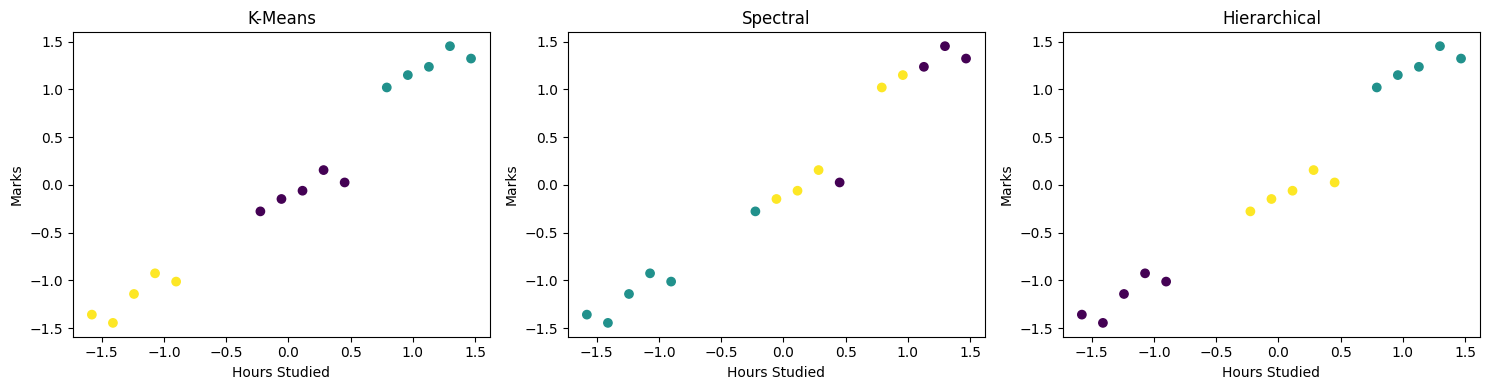

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


    # Dataset
data = {
    'Hours_Studied': [1, 2, 1.5, 2.5, 3,
                      5, 6, 5.5, 6.5, 7,
                      8, 9, 8.5, 9.5, 10],

    'Marks': [30, 35, 28, 40, 38,
              55, 60, 58, 65, 62,
              85, 90, 88, 95, 92]
}

df = pd.DataFrame(data)


# Select features
X = df[['Hours_Studied', 'Marks']]

# Standardize the data
X = StandardScaler().fit_transform(X)

# K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
k_labels = kmeans.fit_predict(X)

# Spectral Clustering
spectral = SpectralClustering(n_clusters=3, affinity='nearest_neighbors',
                              random_state=42)
s_labels = spectral.fit_predict(X)

# Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=3)
h_labels = hierarchical.fit_predict(X)

# Display results
print("K-Means Score:", silhouette_score(X, k_labels))
print("Spectral Score:", silhouette_score(X, s_labels))
print("Hierarchical Score:", silhouette_score(X, h_labels))

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

results = [
    ("K-Means", k_labels),
    ("Spectral", s_labels),
    ("Hierarchical", h_labels)
]

for ax, (name, labels) in zip(axes, results):
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
    ax.set_title(name)
    ax.set_xlabel("Hours Studied")
    ax.set_ylabel("Marks")

plt.tight_layout()
plt.show()